# release_june_26 — detection visualization

Three sensors, one image each, one shared `logs.txt`. Detections are aggregated (deduped by `(x,y,w,h)`) across the full stream and drawn on the corresponding image, matched by sensor UUID = image filename.

Algo mapping (from `images/readme.txt`):

| Sensor UUID prefix | Algo | Notes |
| ------------------ | ---- | ----- |
| `6100002`          | AlgoA | KlymLatest — algotest-10-06-26 |
| `6200001`          | AlgoB | MasterTest |
| `6100001`          | AlgoC | KlymLatest_canDriver |

Parsing/drawing is reused from `../minibatch12/visualize_detections.ipynb`.

In [1]:
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

IMAGES_DIR = Path('images')
LOG_PATH = IMAGES_DIR / 'logs.txt'

SENSORS = [
    ('6100002-2000-000008-2550', 'AlgoA — KlymLatest (algotest-10-06-26)'),
    ('6200001-2000-000008-2550', 'AlgoB — MasterTest'),
    ('6100001-2000-000008-2550', 'AlgoC — KlymLatest_canDriver'),
]

In [2]:
DET_RE = re.compile(
    r'Detection translated for sensor (?P<sensor>[\w-]+):\s*'
    r'pixel\((?P<px>-?\d+),(?P<py>-?\d+)\)\s*->\s*'
    r'cm\((?P<cx>-?\d+),(?P<cy>-?\d+)\)\.\s*'
    r'conf\s*=\s*(?P<conf>[\d.]+);\s*'
    r'box:\s*x\s*=\s*(?P<x>-?\d+),\s*y\s*=\s*(?P<y>-?\d+),\s*'
    r'w\s*=\s*(?P<w>\d+),\s*h\s*=\s*(?P<h>\d+)'
)

def parse_logs(log_path):
    """{sensor: [{x,y,w,h,conf,count,px,py,cx,cy}, ...]} deduped by (x,y,w,h)."""
    buckets = defaultdict(dict)
    for line in log_path.read_text().splitlines():
        m = DET_RE.search(line)
        if not m:
            continue
        s = m.group('sensor')
        box = (int(m['x']), int(m['y']), int(m['w']), int(m['h']))
        conf = float(m['conf'])
        prev = buckets[s].get(box)
        if prev is None:
            buckets[s][box] = dict(
                x=box[0], y=box[1], w=box[2], h=box[3],
                conf=conf, count=1,
                px=int(m['px']), py=int(m['py']),
                cx=int(m['cx']), cy=int(m['cy']),
            )
        else:
            prev['conf'] = max(prev['conf'], conf)
            prev['count'] += 1
    return {s: list(d.values()) for s, d in buckets.items()}

dets_by_sensor = parse_logs(LOG_PATH)
{s[:7]: len(v) for s, v in dets_by_sensor.items()}

{'6100002': 3, '6200001': 2}

In [3]:
def conf_color(conf):
    """Red < 0.5 <= orange < 0.7 <= lime."""
    if conf < 0.5:
        return '#ff3030'
    if conf < 0.7:
        return '#ff9f1c'
    return '#2ecc40'

def draw_detections(ax, img_path, detections, title):
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    for det in detections:
        c = conf_color(det['conf'])
        ax.add_patch(Rectangle(
            (det['x'], det['y']), det['w'], det['h'],
            linewidth=1.6, edgecolor=c, facecolor='none',
        ))
        ax.plot(det['px'], det['py'], marker='+', color=c, markersize=9, mew=1.6)
        label = f"{det['conf']:.2f} (x{det['count']})"
        ax.text(
            det['x'] + 2, max(det['y'] - 3, 8), label,
            fontsize=7, color='white',
            bbox=dict(facecolor=c, edgecolor='none', pad=1, alpha=0.85),
        )

## Rendered detections

Box = bbox, `+` = leg pixel position, label = `conf (xN)` where `N` is how many telemetry frames reported the same `(x,y,w,h)`. Colors: red `<0.5`, orange `<0.7`, green `≥0.7`.

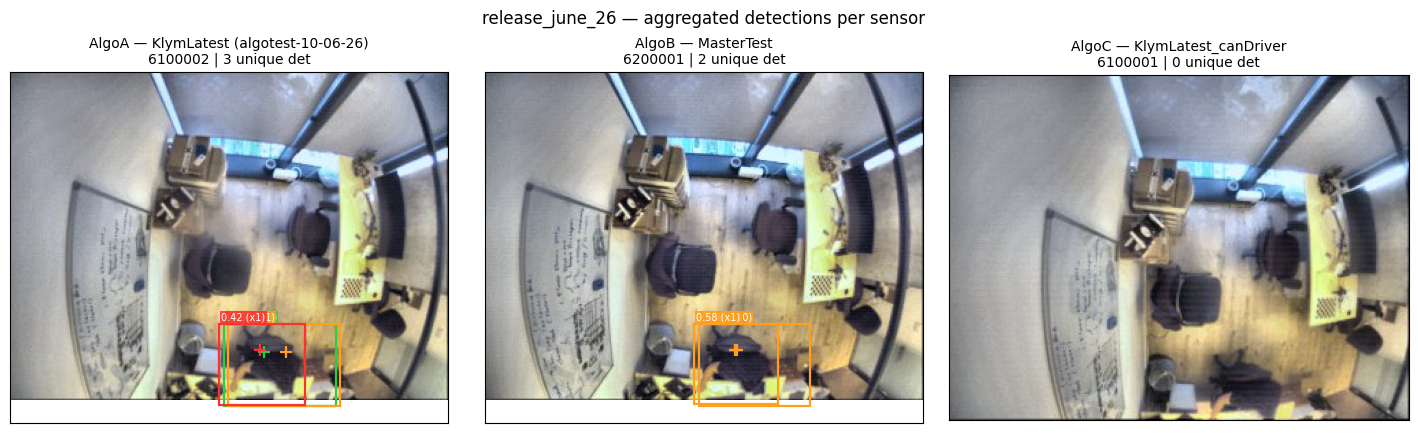

In [4]:
fig, axes = plt.subplots(1, len(SENSORS), figsize=(len(SENSORS) * 4.8, 4.2))

for ax, (sensor, label) in zip(axes, SENSORS):
    img_path = IMAGES_DIR / f'{sensor}.jpg'
    dets = dets_by_sensor.get(sensor, [])
    title = f'{label}\n{sensor[:7]} | {len(dets)} unique det'
    draw_detections(ax, img_path, dets, title)

fig.suptitle('release_june_26 — aggregated detections per sensor', fontsize=12, y=1.02)
fig.tight_layout()
plt.show()